# Machine Learning interpretável e diabetes autorreferido na população adulta brasileira (PNS 2019)

**Objetivo:** identificar quais características demográficas, socioeconômicas, comportamentais e de saúde estão associadas ao diagnóstico médico autorreferido de diabetes em adultos brasileiros. Para isso comparo três classificadores (Regressão Logística, Random Forest e XGBoost) e interpreto o melhor deles com SHAP.

Roteiro:

1. Dados e definição do desfecho
2. Análise exploratória
3. Preparação dos dados
4. Modelagem e avaliação
5. Interpretabilidade (SHAP)
6. Considerações finais

> O desfecho é *diagnóstico médico autorreferido*, e a PNS é uma pesquisa transversal. Os resultados mostram associações, não causas, e o modelo não é uma ferramenta de diagnóstico.

> **Uso de inteligência artificial:** o código deste notebook, as figuras e a execução das análises (incluindo o treinamento dos modelos e o cálculo dos valores SHAP) foram produzidos com o apoio do assistente Claude (Anthropic), via Claude Code.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from pns_utils import DesenhoAmostral, derivar_variaveis, ler_layout_sas, ler_microdados

DIR_EXT, DIR_FIG = RAIZ / "data" / "extracted", RAIZ / "figures"
DIR_FIG.mkdir(exist_ok=True)
SEMENTE = 42

AZUL, LARANJA, VERDE, TINTA, TINTA2, GRADE = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "savefig.dpi": 200, "font.size": 9.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRADE,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA, "legend.frameon": False,
})

## 1. Dados e definição do desfecho

Os microdados vêm do FTP oficial do IBGE (`ftp.ibge.gov.br/PNS/2019/Microdados`). O script `scripts/baixar_dados.py` baixa os arquivos e confere o hash, garantindo que a versão é sempre a mesma. O arquivo é texto de largura fixa; as posições das colunas vêm do programa de leitura publicado pelo IBGE.

**População:** morador selecionado para a entrevista individual (um por domicílio), com entrevista realizada e 18 anos ou mais.

**Desfecho:** resposta "sim" a `Q03001` ("Algum médico já lhe deu o diagnóstico de diabetes?"), excluindo as mulheres cujo diabetes ocorreu apenas na gravidez (`Q03002`). Essa é a definição de Malta et al. (2022).

Um detalhe do questionário: `Q03001` só é perguntado a quem já fez exame de glicemia. Quem nunca fez entra como "sem diagnóstico", a mesma convenção do IBGE.

In [2]:
if not (DIR_EXT / "PNS_2019.txt").exists():
    subprocess.run([sys.executable, str(RAIZ / "scripts" / "baixar_dados.py")], check=True)

VARIAVEIS = (
    "V0001 V0024 UPA_PNS V0006_PNS V0015 V0025A M001 V0026 V00291 V00292 V00293 "
    "C006 C008 C009 VDD004A VDF003 VDF004 VDE001 VDE002 I00102 "
    "P050 P052 P027 P03201 P034 P035 P03701 P03702 P036 P02601 P018 P00901 P02002 P02501 "
    "P00104 P00404 P00405 P005 Q00101 Q00201 Q00202 Q05901 Q060 Q06306 Q068 N001 "
    "Q02901 Q03001 Q03002 Q031"
).split()

layout = ler_layout_sas(DIR_EXT / "input_PNS_2019.txt")
bruto = ler_microdados(DIR_EXT / "PNS_2019.txt", layout, VARIAVEIS)

selecionados = bruto[(bruto.V0015 == "01") & (bruto.V0025A == "1") & (bruto.M001 == "1")].reset_index(drop=True)
df = derivar_variaveis(selecionados)   # desfecho e variáveis analíticas (ver src/pns_utils.py)
adultos = df[df.adulto]

print(f"Registros no arquivo:                 {len(bruto):>7,}")
print(f"Moradores selecionados entrevistados: {len(selecionados):>7,}")
print(f"Adultos (18+):                        {len(adultos):>7,}")
print(f"Casos de diabetes autorreferido:      {int(adultos.diabetes.sum()):>7,} "
      f"({adultos.diabetes.mean():.1%} da amostra, sem ponderação)")

Registros no arquivo:                 293,726
Moradores selecionados entrevistados:  90,846
Adultos (18+):                         88,531
Casos de diabetes autorreferido:        7,088 (8.0% da amostra, sem ponderação)


## 2. Análise exploratória

A PNS tem amostragem complexa (estratos, conglomerados e pesos calibrados). Para que as prevalências representem a população brasileira, uso o peso do morador selecionado (`V00291`) e calculo os intervalos de confiança considerando estratos e UPAs.

In [3]:
desenho = DesenhoAmostral(df)
ADULTO = df.adulto.to_numpy()
geral = desenho.proporcao(df.diabetes, ADULTO)
print(f"Prevalência de diabetes autorreferido: {geral['estimativa']:.1%} "
      f"(IC95% {geral['ic_inf']:.1%} a {geral['ic_sup']:.1%})")
print(f"Equivale a {geral['total_casos'] / 1e6:.1f} milhões de adultos")

Prevalência de diabetes autorreferido: 7.7% (IC95% 7.4% a 8.0%)
Equivale a 12.3 milhões de adultos


O valor é o mesmo publicado por Malta et al. (2022), 7,7% (IC95% 7,4–8,0), o que confirma que a leitura dos dados e a definição do desfecho estão corretas.

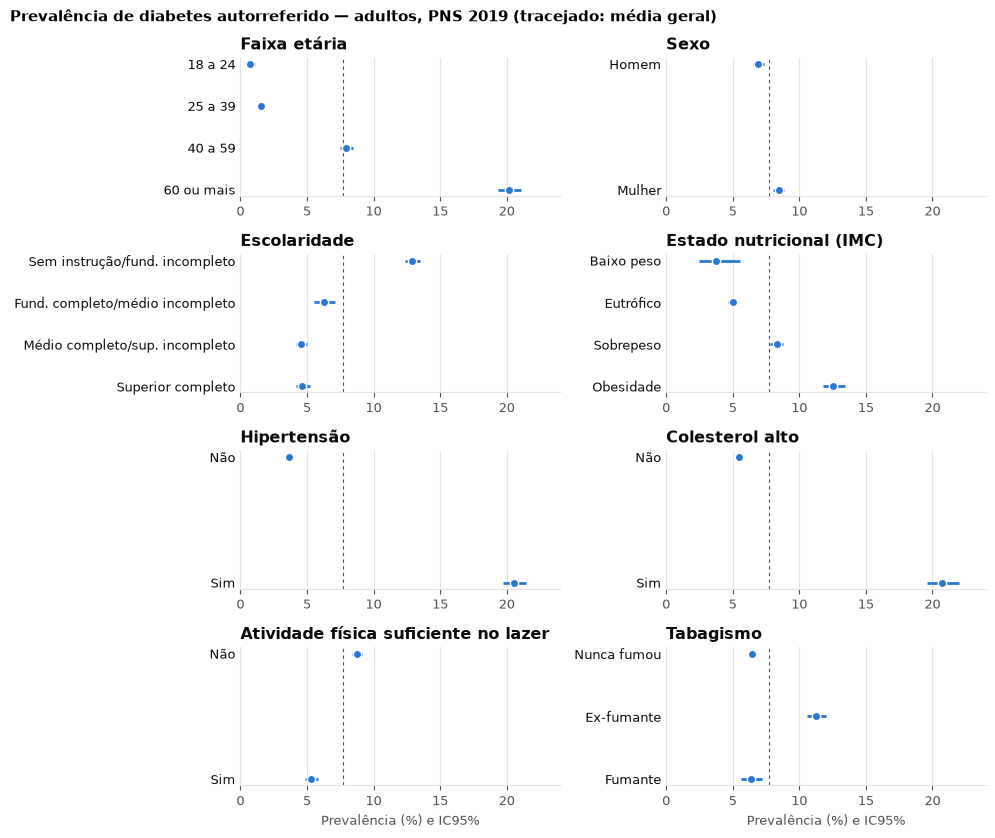

,variavel,categoria,n,casos_amostra,prevalencia_pct,ic95_inf,ic95_sup
0,faixa_etaria,18 a 24,8145,55,0.7,0.5,1.1
1,faixa_etaria,25 a 39,25399,327,1.6,1.3,1.9
2,faixa_etaria,40 a 59,32259,2432,7.9,7.4,8.5
3,faixa_etaria,60 ou mais,22728,4274,20.2,19.3,21.1
4,sexo,Homem,41662,2878,6.9,6.5,7.3
5,sexo,Mulher,46869,4210,8.4,8.1,8.8
6,escolaridade,Sem instrução/fund. incompleto,35572,4249,12.9,12.3,13.5
7,escolaridade,Fund. completo/médio incompleto,12005,779,6.3,5.5,7.1
8,escolaridade,Médio completo/sup. incompleto,27337,1350,4.6,4.2,5.0
9,escolaridade,Superior completo,13617,710,4.7,4.1,5.2


In [4]:
VARS_EXPLORA = {
    "faixa_etaria": "Faixa etária", "sexo": "Sexo", "escolaridade": "Escolaridade",
    "estado_nutricional": "Estado nutricional (IMC)", "hipertensao": "Hipertensão",
    "colesterol_alto": "Colesterol alto", "af_lazer_suficiente": "Atividade física suficiente no lazer",
    "tabagismo": "Tabagismo",
}
prev = pd.concat([desenho.prevalencia_por("diabetes", v, ADULTO) for v in VARS_EXPLORA], ignore_index=True)

fig, axes = plt.subplots(4, 2, figsize=(10, 8.5))
for ax, (v, titulo) in zip(axes.flat, VARS_EXPLORA.items()):
    t = prev[prev.variavel == v]
    y = np.arange(len(t))[::-1]
    ax.axvline(geral["estimativa"] * 100, color=TINTA2, lw=0.8, ls=(0, (3, 3)))
    ax.hlines(y, t.ic_inf * 100, t.ic_sup * 100, color=AZUL, lw=2)
    ax.plot(t.estimativa * 100, y, "o", color=AZUL, ms=6, mec="white", mew=1)
    ax.set_yticks(y, t.categoria)
    ax.set_xlim(0, 24)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(titulo, loc="left", fontweight="bold", color=TINTA)
for ax in axes[-1]:
    ax.set_xlabel("Prevalência (%) e IC95%")
fig.suptitle("Prevalência de diabetes autorreferido — adultos, PNS 2019 (tracejado: média geral)",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(DIR_FIG / "prevalencia_por_grupo.png", bbox_inches="tight")
plt.show()

tabela_prev = prev.assign(
    prevalencia_pct=(prev.estimativa * 100).round(1),
    ic95_inf=(prev.ic_inf * 100).round(1),
    ic95_sup=(prev.ic_sup * 100).round(1),
)[["variavel", "categoria", "n", "casos_amostra", "prevalencia_pct", "ic95_inf", "ic95_sup"]]
tabela_prev.to_csv(DIR_FIG / "prevalencia_por_grupo.csv", index=False)
tabela_prev

In [5]:
# Há quanto tempo os casos foram diagnosticados? (idade atual − idade no diagnóstico, Q031)
CASO = ADULTO & (df.diabetes == 1).to_numpy()
ha_5_anos = desenho.proporcao((df.anos_desde_diagnostico_dm >= 5).astype(float), CASO)
print(f"Casos diagnosticados há 5 anos ou mais: {ha_5_anos['estimativa']:.1%}")

Casos diagnosticados há 5 anos ou mais: 65.4%


**O que aparece:**

- **Idade** é o gradiente mais forte: menos de 1% entre 18 e 24 anos e cerca de 20% a partir dos 60.
- A prevalência sobe com o **IMC** e é bem maior em quem relata **hipertensão** ou **colesterol alto** (em torno de 20%).
- Há gradiente por **escolaridade**: a prevalência é maior entre quem tem menos estudo, em parte porque as gerações mais velhas estudaram menos.
- Alguns hábitos aparecem "ao contrário". **Ex-fumantes** têm mais diabetes que fumantes, e quem pratica atividade física tem menos. Parte disso é **causalidade reversa**: depois do diagnóstico, muita gente muda de hábitos. Na PNS, cerca de dois terços dos casos foram diagnosticados há 5 anos ou mais.

## 3. Preparação dos dados

### Variáveis preditoras

Escolhi fatores com base na literatura sobre diabetes tipo 2 e no estudo de referência:

| Grupo | Variáveis |
|---|---|
| Demográficas | idade, sexo, raça/cor, região, zona rural |
| Socioeconômicas | escolaridade, renda per capita (faixas de salário mínimo), plano de saúde |
| Comportamentais | tabagismo, consumo abusivo de álcool, atividade física no lazer |
| Saúde | IMC (peso e altura referidos), hipertensão, colesterol alto |

### O que ficou de fora para evitar vazamento de dados

| Variável | Motivo |
|---|---|
| Tratamento e acompanhamento do diabetes (`Q031`–`Q039`) | só existem para quem já tem o diagnóstico |
| Último exame de glicemia (`Q02901`) | é o filtro da pergunta do desfecho; quem nunca fez é sempre "sem diagnóstico" |
| Doença do coração e AVC | podem ser complicações do próprio diabetes |
| Autoavaliação de saúde | pode ser consequência da doença |

**Gestantes** (e mulheres que não sabiam se estavam grávidas) saem da modelagem, porque o IBGE não coleta peso e altura delas. A escolaridade e a renda entram como ordinais (0 a 3); as demais variáveis categóricas viram indicadores 0/1.

In [6]:
base = adultos[adultos.imc.notna() & adultos.renda_sm.notna() & adultos.raca_cor.notna()].copy()
print(f"Excluídos sem IMC (gestantes) ou com renda/raça ignorada: {len(adultos) - len(base)}")

X = pd.DataFrame({
    "Idade": base.idade,
    "IMC": base.imc,
    "Sexo feminino": (base.sexo == "Mulher").astype(int),
    "Escolaridade": base.escolaridade.cat.codes,
    "Renda (faixa SM)": base.renda_sm.cat.codes,
    "Raça preta": (base.raca_cor == "Preta").astype(int),
    "Raça parda": (base.raca_cor == "Parda").astype(int),
    "Raça amarela/indígena": (base.raca_cor == "Amarela/Indígena").astype(int),
    "Região Norte": (base.regiao == "Norte").astype(int),
    "Região Nordeste": (base.regiao == "Nordeste").astype(int),
    "Região Sul": (base.regiao == "Sul").astype(int),
    "Região Centro-Oeste": (base.regiao == "Centro-Oeste").astype(int),
    "Zona rural": (base.situacao == "Rural").astype(int),
    "Plano de saúde": (base.plano_saude == "Sim").astype(int),
    "Hipertensão": (base.hipertensao == "Sim").astype(int),
    "Colesterol alto": (base.colesterol_alto == "Sim").astype(int),
    "Ex-fumante": (base.tabagismo == "Ex-fumante").astype(int),
    "Fumante": (base.tabagismo == "Fumante").astype(int),
    "Álcool abusivo": (base.alcool_abusivo == "Sim").astype(int),
    "Atividade física suficiente": (base.af_lazer_suficiente == "Sim").astype(int),
})
y = base.diabetes.astype(int)
assert X.notna().all().all() and (X.min() >= 0).all()
print(f"Base de modelagem: {X.shape[0]:,} adultos × {X.shape[1]} variáveis | casos: {y.sum():,} ({y.mean():.1%})")

Excluídos sem IMC (gestantes) ou com renda/raça ignorada: 883
Base de modelagem: 87,648 adultos × 20 variáveis | casos: 7,076 (8.1%)


Divisão treino/teste (80/20) **estratificada pelo desfecho**, para manter a mesma proporção de casos nos dois conjuntos. O conjunto de teste só é usado na avaliação final.

In [7]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMENTE)
print(f"Treino: {len(X_tr):,} ({y_tr.mean():.1%} casos) | Teste: {len(X_te):,} ({y_te.mean():.1%} casos)")

Treino: 70,118 (8.1% casos) | Teste: 17,530 (8.1% casos)


## 4. Modelagem e avaliação

Os três modelos lidam com o **desbalanceamento** (só ~8% de casos) dando mais peso à classe positiva durante o treino: `class_weight="balanced"` na Regressão Logística e na Random Forest, e `scale_pos_weight` no XGBoost. Sem isso, os modelos tenderiam a prever "sem diagnóstico" para quase todo mundo.

Os hiperparâmetros são valores moderados, escolhidos para evitar sobreajuste (árvores rasas no XGBoost, folhas com pelo menos 20 pessoas na Random Forest). Primeiro comparo os modelos com **validação cruzada estratificada de 5 partes** no conjunto de treino.

In [8]:
razao = (y_tr == 0).sum() / (y_tr == 1).sum()
modelos = {
    "Regressão Logística": make_pipeline(
        StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=20, max_features="sqrt",
        class_weight="balanced_subsample", n_jobs=-1, random_state=SEMENTE),
    "XGBoost": XGBClassifier(
        n_estimators=400, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=razao, eval_metric="logloss", n_jobs=-1, random_state=SEMENTE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
res_cv = {nome: cross_val_score(m, X_tr, y_tr, cv=cv, scoring="roc_auc", n_jobs=1) for nome, m in modelos.items()}
pd.DataFrame({n: {"ROC-AUC médio (CV)": s.mean(), "desvio-padrão": s.std()} for n, s in res_cv.items()}).T.round(3)

,ROC-AUC médio (CV),desvio-padrão
Regressão Logística,0.826,0.007
Random Forest,0.829,0.007
XGBoost,0.829,0.007


Agora cada modelo é treinado com todo o conjunto de treino e avaliado no teste. Uso o limiar padrão de 0,5 sobre a probabilidade prevista. Por causa do balanceamento de classes, esse limiar favorece a **sensibilidade** (encontrar os casos) em troca de mais falsos positivos.

In [9]:
def metricas(y_true, prob, limiar=0.5):
    pred = (prob >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"ROC-AUC": roc_auc_score(y_true, prob), "Sensibilidade (recall)": recall_score(y_true, pred),
            "Especificidade": tn / (tn + fp), "Precisão": precision_score(y_true, pred),
            "F1-score": f1_score(y_true, pred), "Acurácia": (tp + tn) / len(y_true)}


probs = {}
for nome, m in modelos.items():
    m.fit(X_tr, y_tr)
    probs[nome] = m.predict_proba(X_te)[:, 1]

tabela = pd.DataFrame({n: metricas(y_te, p) for n, p in probs.items()}).T.round(3)
tabela.to_csv(DIR_FIG / "metricas_teste.csv")
tabela

,ROC-AUC,Sensibilidade (recall),Especificidade,Precisão,F1-score,Acurácia
Regressão Logística,0.826,0.776,0.745,0.211,0.331,0.747
Random Forest,0.831,0.734,0.777,0.224,0.344,0.774
XGBoost,0.830,0.816,0.712,0.199,0.320,0.721


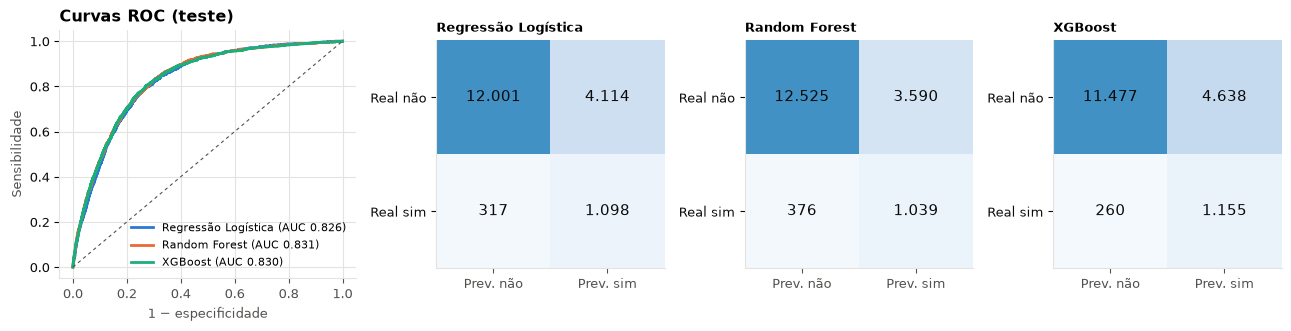

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), gridspec_kw={"width_ratios": [1.3, 1, 1, 1]})
cores = {"Regressão Logística": AZUL, "Random Forest": LARANJA, "XGBoost": VERDE}
ax = axes[0]
for nome, p in probs.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    ax.plot(fpr, tpr, color=cores[nome], lw=2, label=f"{nome} (AUC {roc_auc_score(y_te, p):.3f})")
ax.plot([0, 1], [0, 1], color=TINTA2, lw=0.8, ls=(0, (3, 3)))
ax.set_xlabel("1 − especificidade")
ax.set_ylabel("Sensibilidade")
ax.set_title("Curvas ROC (teste)", loc="left", fontweight="bold")
ax.legend(loc="lower right", fontsize=8)

for ax, (nome, p) in zip(axes[1:], probs.items()):
    cm = confusion_matrix(y_te, (p >= 0.5).astype(int))
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.6)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}".replace(",", "."), ha="center", va="center", fontsize=11, color=TINTA)
    ax.set_xticks([0, 1], ["Prev. não", "Prev. sim"])
    ax.set_yticks([0, 1], ["Real não", "Real sim"])
    ax.grid(False)
    ax.set_title(nome, loc="left", fontweight="bold", fontsize=9.5)
fig.tight_layout()
fig.savefig(DIR_FIG / "roc_matrizes.png", bbox_inches="tight")
plt.show()

**Leitura dos resultados.**

- Os três modelos ficaram **praticamente empatados**: ROC-AUC de 0,826 (Regressão Logística), 0,831 (Random Forest) e 0,830 (XGBoost) no teste, com valores quase iguais na validação cruzada (desvio-padrão de 0,007). As curvas ROC se sobrepõem. Com essas variáveis, os modelos mais flexíveis não acrescentam quase nada à Regressão Logística, o que indica relações próximas do aditivo/linear.
- Com o limiar de 0,5, os modelos encontram de **73% a 82% dos casos** (sensibilidade) e acertam de **71% a 78% dos não casos** (especificidade). O XGBoost tem a maior sensibilidade (81,6%), e a Random Forest a maior especificidade (77,7%).
- A **precisão é baixa** (cerca de 20%): de cada 5 pessoas sinalizadas, só 1 relata diagnóstico. Isso é esperado quando só 8% da população é positiva, e por isso a acurácia sozinha seria enganosa. Também é um dos motivos pelos quais o modelo não serve como ferramenta de diagnóstico.

Sigo com o **XGBoost** para a interpretação com SHAP. Ele teve a maior sensibilidade e é o que pode capturar relações não lineares, como a da idade.

## 5. Interpretabilidade com SHAP

O SHAP decompõe cada predição na contribuição de cada variável, a partir de uma referência média. Calculo os valores SHAP no conjunto de teste para o XGBoost. Para comparação, também mostro as razões de chances (*odds ratios*) da Regressão Logística, que é o modelo de interpretação mais direta.

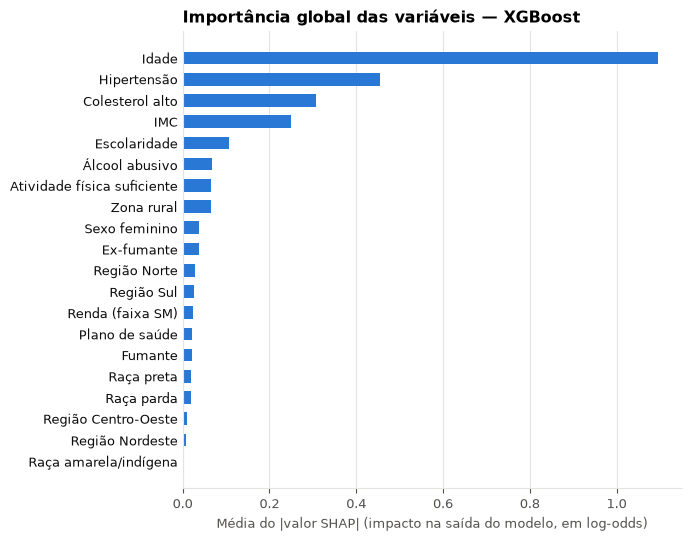

In [11]:
xgb = modelos["XGBoost"]
explainer = shap.TreeExplainer(xgb)
valores_shap = explainer(X_te)

importancia = pd.Series(np.abs(valores_shap.values).mean(axis=0), index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(importancia.index, importancia.values, color=AZUL, height=0.6)
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_xlabel("Média do |valor SHAP| (impacto na saída do modelo, em log-odds)")
ax.set_title("Importância global das variáveis — XGBoost", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(DIR_FIG / "shap_importancia.png", bbox_inches="tight")
plt.show()

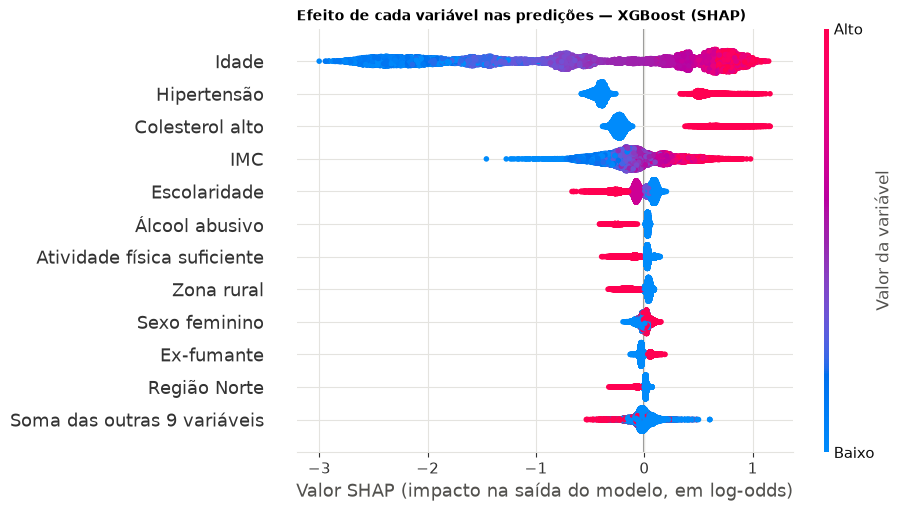

In [12]:
shap.plots.beeswarm(valores_shap, max_display=12, show=False, plot_size=(8, 5.5))
fig = plt.gcf()
ax_principal, ax_cor = fig.axes[0], fig.axes[-1]
ax_principal.set_xlabel("Valor SHAP (impacto na saída do modelo, em log-odds)")
ax_principal.set_yticklabels([r.get_text().replace("Sum of", "Soma das outras").replace("other features", "variáveis")
                              for r in ax_principal.get_yticklabels()])
ax_cor.set_ylabel("Valor da variável")
ax_cor.set_yticklabels(["Baixo", "Alto"])
plt.title("Efeito de cada variável nas predições — XGBoost (SHAP)", loc="left", fontweight="bold", fontsize=10)
plt.gcf().savefig(DIR_FIG / "shap_beeswarm.png", bbox_inches="tight")
plt.show()

Como ler o gráfico acima: cada ponto é uma pessoa do teste. A cor indica o valor da variável (vermelho = alto, azul = baixo), e a posição horizontal indica quanto aquela característica empurrou a predição para "diabetes" (direita) ou para "sem diagnóstico" (esquerda).

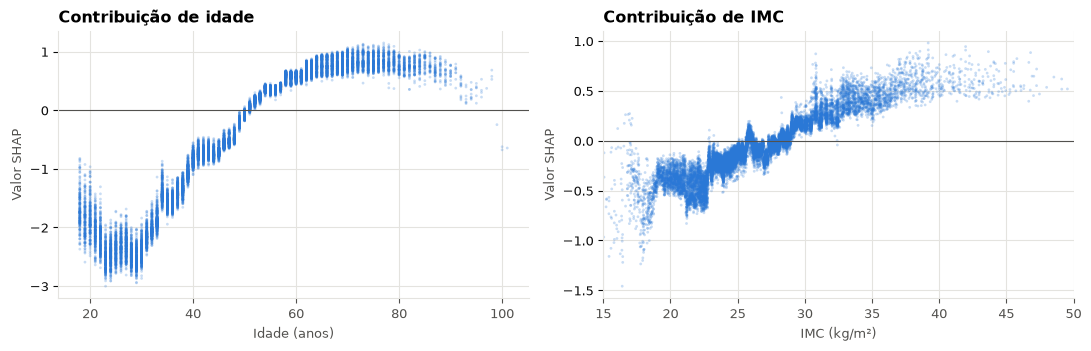

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, var in zip(axes, ["Idade", "IMC"]):
    i = list(X.columns).index(var)
    ax.scatter(X_te[var], valores_shap.values[:, i], s=4, alpha=0.25, color=AZUL, edgecolors="none")
    ax.axhline(0, color=TINTA2, lw=0.8)
    ax.set_xlabel(var + (" (anos)" if var == "Idade" else " (kg/m²)"))
    ax.set_ylabel("Valor SHAP")
    ax.set_title(f"Contribuição de {var.lower() if var == 'Idade' else var}", loc="left", fontweight="bold")
axes[1].set_xlim(15, 50)
fig.tight_layout()
fig.savefig(DIR_FIG / "shap_dependencia.png", bbox_inches="tight")
plt.show()

In [14]:
# Razões de chances (OR) da Regressão Logística, voltando à escala original das variáveis.
# Binárias: sim vs. não | Idade: a cada 10 anos | IMC: a cada 5 kg/m² | Escolaridade e renda: a cada nível.
# Obs.: o class_weight altera o intercepto, mas não as razões de chances.
escalonador, rl = modelos["Regressão Logística"][0], modelos["Regressão Logística"][-1]
coef = rl.coef_[0] / escalonador.scale_
unidade = pd.Series(1.0, index=X.columns)
unidade[["Idade", "IMC"]] = [10, 5]
or_tab = pd.DataFrame({"OR": np.exp(coef * unidade.values), "unidade": unidade.map(
    {1.0: "sim vs. não / +1 nível", 10: "+10 anos", 5: "+5 kg/m²"})}, index=X.columns)
or_tab.sort_values("OR", ascending=False).round(2)

,OR,unidade
Colesterol alto,2.67,sim vs. não / +1 nível
Hipertensão,2.48,sim vs. não / +1 nível
Idade,1.64,+10 anos
IMC,1.35,+5 kg/m²
Raça amarela/indígena,1.33,sim vs. não / +1 nível
Raça preta,1.15,sim vs. não / +1 nível
Ex-fumante,1.14,sim vs. não / +1 nível
Raça parda,1.08,sim vs. não / +1 nível
Região Centro-Oeste,1.05,sim vs. não / +1 nível
Plano de saúde,1.04,sim vs. não / +1 nível


**Leitura da interpretabilidade.**

- **Idade** é, de longe, a variável mais importante. O gráfico de dependência mostra que a contribuição é fortemente negativa até cerca de 35 anos, cruza o zero por volta dos 50, atinge o máximo entre 65 e 80 anos e cai um pouco depois. Essa queda nas idades mais altas pode refletir mortalidade seletiva, mas aqui é só uma hipótese.
- **Hipertensão** e **colesterol alto** vêm em seguida, coerentes com a agregação de fatores cardiometabólicos descrita na literatura.
- **IMC** tem efeito crescente: puxa a predição para baixo até cerca de 28 kg/m² e para cima a partir daí, até se estabilizar por volta de 40 kg/m².
- **Escolaridade** mais alta reduz a predição, o que reforça o gradiente social do diabetes.
- **Consumo abusivo de álcool** e **atividade física suficiente** aparecem *reduzindo* a predição, e **ex-fumante** aumentando. Isso não significa que beber protege contra diabetes. É o padrão de causalidade reversa visto na exploração: a maioria dos casos foi diagnosticada anos antes da entrevista, e muita gente muda de hábitos depois do diagnóstico.
- A Regressão Logística destaca **as mesmas quatro variáveis**: colesterol alto (OR 2,67), hipertensão (OR 2,48), idade (OR 1,64 a cada 10 anos) e IMC (OR 1,35 a cada 5 kg/m²). Também repete os sinais de escolaridade (OR 0,89 por nível), atividade física (0,87) e álcool abusivo (0,75). A concordância entre modelos tão diferentes dá consistência aos resultados.

## 6. Considerações finais

- A prevalência de diabetes autorreferido em adultos brasileiros foi de **7,7%** em 2019, cerca de 12,3 milhões de pessoas, igual à publicada na literatura com a mesma base.
- Os três algoritmos tiveram desempenho semelhante (**ROC-AUC ≈ 0,83**). Neste problema, a Regressão Logística é tão boa quanto os métodos de *ensemble* e mais simples de explicar.
- O SHAP mostrou que o modelo se apoia principalmente em **idade, hipertensão, colesterol alto e IMC**, coerente com a literatura sobre diabetes tipo 2, e ainda revelou a forma não linear do efeito da idade.

**Limitações**

- Desfecho autorreferido: pessoas com diabetes não diagnosticado aparecem como "não caso", e o diagnóstico depende de acesso a serviços de saúde.
- Desenho transversal: sem temporalidade, os hábitos medidos podem ser consequência do diagnóstico (causalidade reversa).
- Peso e altura são referidos (e imputados pelo IBGE em parte dos casos).
- A PNS não distingue diabetes tipo 1 de tipo 2.
- Os modelos foram treinados sem os pesos amostrais. As prevalências descritivas usam o desenho completo, mas as métricas de desempenho valem para a amostra, não necessariamente para a população.

**Trabalhos futuros:** validar o modelo com dados de glicemia ou hemoglobina glicada medidas (como a subamostra de exames laboratoriais da PNS 2013), testar ajuste de limiar e incorporar os pesos amostrais no treino.